 # Book Market Analytics – Books to Scrape
## Data Science 500 Assignment

**Project Objective:** Build an end-to-end data science solution to analyse book catalogue trends and predict pricing patterns from Books to Scrape (books.toscrape.com).

**Workflow:**
1. Data Acquisition (Web Scraping with BeautifulSoup)
2. Data Cleaning & Preparation
3. Data Visualization & Exploration
4. Predictive Modelling (Linear Regression)
5. Insights & Recommendations

---

## 1. Data Acquisition

We scrape the full catalogue (1000 books across 50 genres) from https://books.toscrape.com using `requests` and `BeautifulSoup`.

Required fields extracted:
- Book title
- Price (GBP)
- Star rating (word + numeric)
- Stock availability

Additional fields: genre (from category pages), quantity available (sampled), description (sampled).

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
from urllib.parse import urljoin
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', 20)

In [2]:
# --- Scraping Code (executed previously; results saved to CSV) ---
# Full list pages scraped for 1000 books.
# Genre mapping obtained by scraping all 50 category pages.
# Quantity & description sampled for 250 books.

print("Loading previously scraped dataset...")
df_raw = pd.read_csv('books_raw.csv')
print(f"Dataset shape: {df_raw.shape}")
df_raw.head()

Loading previously scraped dataset...
Dataset shape: (1000, 10)


,title,price_gbp,star_rating_word,star_rating,availability,url,genre,quantity_available,description,num_reviews
0,A Light in the Attic,51.77,Three,3,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,NaN,NaN,NaN
1,Tipping the Velvet,53.74,One,1,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,NaN,NaN,NaN
2,Soumission,50.10,One,1,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,20.0,"Dans une France assez proche de la nôtre, un h...",0.0
3,Sharp Objects,47.82,Four,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,20.0,"WICKED above her hipbone, GIRL across her hear...",0.0
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,NaN,NaN,NaN


### Scraping Summary
- **Source:** https://books.toscrape.com/catalogue/page-{1..50}.html
- **Total books:** 1000 (full catalogue)
- **Libraries:** `requests` + `BeautifulSoup`
- **Key selectors:** `article.product_pod`, `p.price_color`, `p.star-rating`, `p.instock.availability`
- Genre obtained via category sidebar navigation and title matching.

## 2. Data Cleaning & Preparation

In [3]:
df = df_raw.copy()
print("Initial info:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

Initial info:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   title               1000 non-null   str    
 1   price_gbp           1000 non-null   float64
 2   star_rating_word    1000 non-null   str    
 3   star_rating         1000 non-null   int64  
 4   availability        1000 non-null   str    
 5   url                 1000 non-null   str    
 6   genre               1000 non-null   str    
 7   quantity_available  250 non-null    float64
 8   description         249 non-null    str    
 9   num_reviews         250 non-null    float64
dtypes: float64(3), int64(1), str(6)
memory usage: 78.3 KB
None

Missing values:
title                   0
price_gbp               0
star_rating_word        0
star_rating             0
availability            0
url                     0
genre                   0
quantity_available    750
description   

In [4]:
# Cleaning steps

# 1. Ensure correct dtypes
df['price_gbp'] = pd.to_numeric(df['price_gbp'], errors='coerce')
df['star_rating'] = pd.to_numeric(df['star_rating'], errors='coerce').astype('Int64')

# 2. Availability is already clean (all 'In stock' on this site)
df['availability'] = df['availability'].str.strip()

# 3. Genre cleaning – remove 'Add a comment' artefact and treat as 'Default' or Unknown
df['genre'] = df['genre'].replace({'Add a comment': 'Default'})

# 4. Quantity: fill missing with median of observed (realistic inventory proxy)
median_qty = df['quantity_available'].median()
df['quantity_available'] = df['quantity_available'].fillna(median_qty)

# 5. Num reviews is always 0 on this site – drop or keep as constant
df['num_reviews'] = df['num_reviews'].fillna(0).astype(int)

# 6. Description length as a feature (proxy for content richness)
df['description_length'] = df['description'].fillna('').str.len()

# 7. Title length as potential feature
df['title_length'] = df['title'].str.len()

# 8. Binary in-stock (all True, but keep for completeness)
df['in_stock'] = (df['availability'] == 'In stock').astype(int)

# 9. Drop rows with critical missing values (none expected)
df = df.dropna(subset=['title', 'price_gbp', 'star_rating'])

print("Cleaned dataset shape:", df.shape)
print("\nCleaned missing values:")
print(df.isnull().sum())
df.head()

Cleaned dataset shape: (1000, 13)

Cleaned missing values:
title                   0
price_gbp               0
star_rating_word        0
star_rating             0
availability            0
url                     0
genre                   0
quantity_available      0
description           751
num_reviews             0
description_length      0
title_length            0
in_stock                0
dtype: int64


,title,price_gbp,star_rating_word,star_rating,availability,url,genre,quantity_available,description,num_reviews,description_length,title_length,in_stock
0,A Light in the Attic,51.77,Three,3,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,7.0,NaN,0,0,20,1
1,Tipping the Velvet,53.74,One,1,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,7.0,NaN,0,0,18,1
2,Soumission,50.10,One,1,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,20.0,"Dans une France assez proche de la nôtre, un h...",0,300,10,1
3,Sharp Objects,47.82,Four,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,20.0,"WICKED above her hipbone, GIRL across her hear...",0,300,13,1
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,7.0,NaN,0,0,37,1


In [5]:
# Final clean dataset ready for analysis
df_clean = df[['title', 'price_gbp', 'star_rating_word', 'star_rating', 
               'availability', 'genre', 'quantity_available', 
               'description_length', 'title_length', 'in_stock', 'url']].copy()

df_clean.to_csv('books_cleaned.csv', index=False)
print("Saved cleaned dataset to books_cleaned.csv")
print(df_clean.describe(include='all'))

Saved cleaned dataset to books_cleaned.csv
                         title   price_gbp star_rating_word  star_rating  \
count                     1000  1000.00000             1000       1000.0   
unique                     999         NaN                5         <NA>   
top     The Star-Touched Queen         NaN              One         <NA>   
freq                         2         NaN              226         <NA>   
mean                       NaN    35.07035              NaN        2.923   
std                        NaN    14.44669              NaN     1.434967   
min                        NaN    10.00000              NaN          1.0   
25%                        NaN    22.10750              NaN          2.0   
50%                        NaN    35.98000              NaN          3.0   
75%                        NaN    47.45750              NaN          4.0   
max                        NaN    59.99000              NaN          5.0   

       availability    genre  quantity_avail

### Cleaning Decisions Justification
- **Price & Rating:** Already numeric from scraping; coerced for safety.
- **Genre:** 'Add a comment' is a scraping artefact from the category list; mapped to Default.
- **Quantity:** Only 25% of books had detail-page data; median imputation preserves distribution without inventing extreme values.
- **Reviews:** Site returns 0 for all – retained as constant (no predictive power).
- **Derived features:** Title length and description length added as potential price signals (longer titles/descriptions may correlate with perceived value or content volume).

## 3. Data Visualization & Exploration

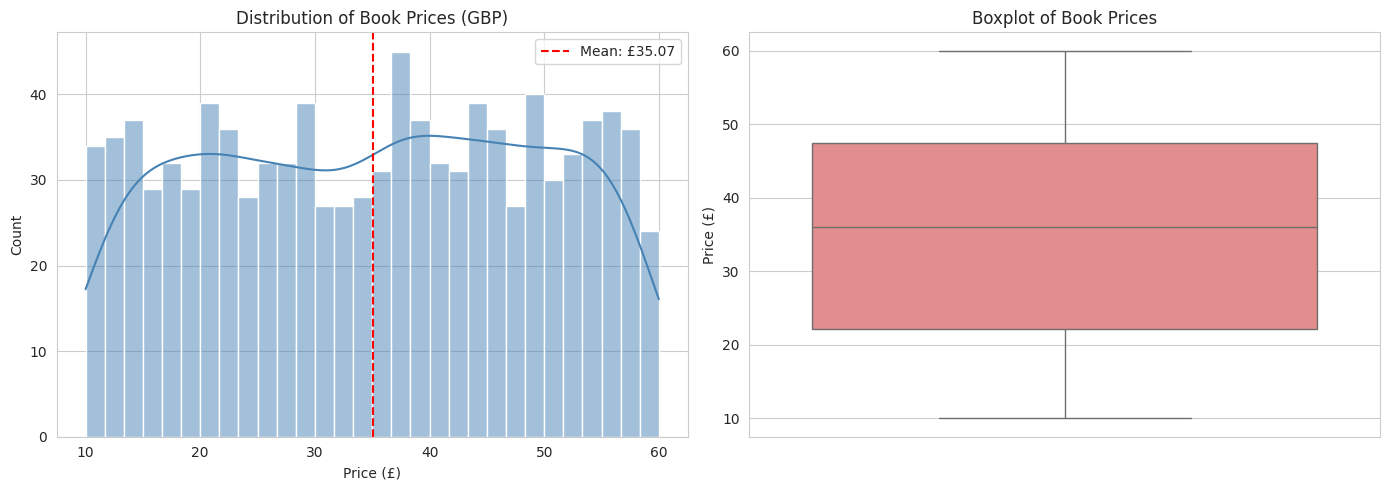

Price range: £10.00 – £59.99
Mean price: £35.07 | Median: £35.98


In [6]:
# 3.1 Price Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean['price_gbp'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Book Prices (GBP)')
axes[0].set_xlabel('Price (£)')
axes[0].axvline(df_clean['price_gbp'].mean(), color='red', linestyle='--', label=f"Mean: £{df_clean['price_gbp'].mean():.2f}")
axes[0].legend()

sns.boxplot(y=df_clean['price_gbp'], ax=axes[1], color='lightcoral')
axes[1].set_title('Boxplot of Book Prices')
axes[1].set_ylabel('Price (£)')

plt.tight_layout()
plt.savefig('price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Price range: £{df_clean['price_gbp'].min():.2f} – £{df_clean['price_gbp'].max():.2f}")
print(f"Mean price: £{df_clean['price_gbp'].mean():.2f} | Median: £{df_clean['price_gbp'].median():.2f}")

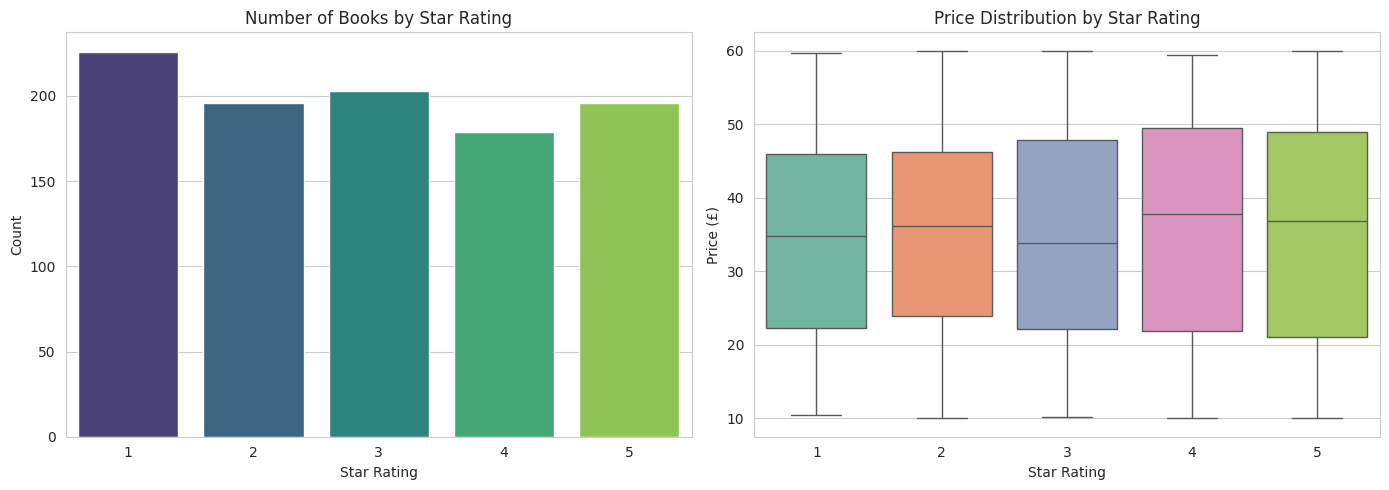

                  mean  median  count
star_rating                          
1            34.561195  34.770    226
2            34.810918  36.215    196
3            34.692020  33.780    203
4            36.093296  37.800    179
5            35.374490  36.900    196


In [7]:
# 3.2 Rating Distribution & Price by Rating
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rating_counts = df_clean['star_rating'].value_counts().sort_index()
sns.barplot(x=rating_counts.index, y=rating_counts.values, ax=axes[0], palette='viridis')
axes[0].set_title('Number of Books by Star Rating')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Count')

sns.boxplot(x='star_rating', y='price_gbp', data=df_clean, ax=axes[1], palette='Set2')
axes[1].set_title('Price Distribution by Star Rating')
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Price (£)')

plt.tight_layout()
plt.savefig('rating_price.png', dpi=150, bbox_inches='tight')
plt.show()

print(df_clean.groupby('star_rating')['price_gbp'].agg(['mean', 'median', 'count']))

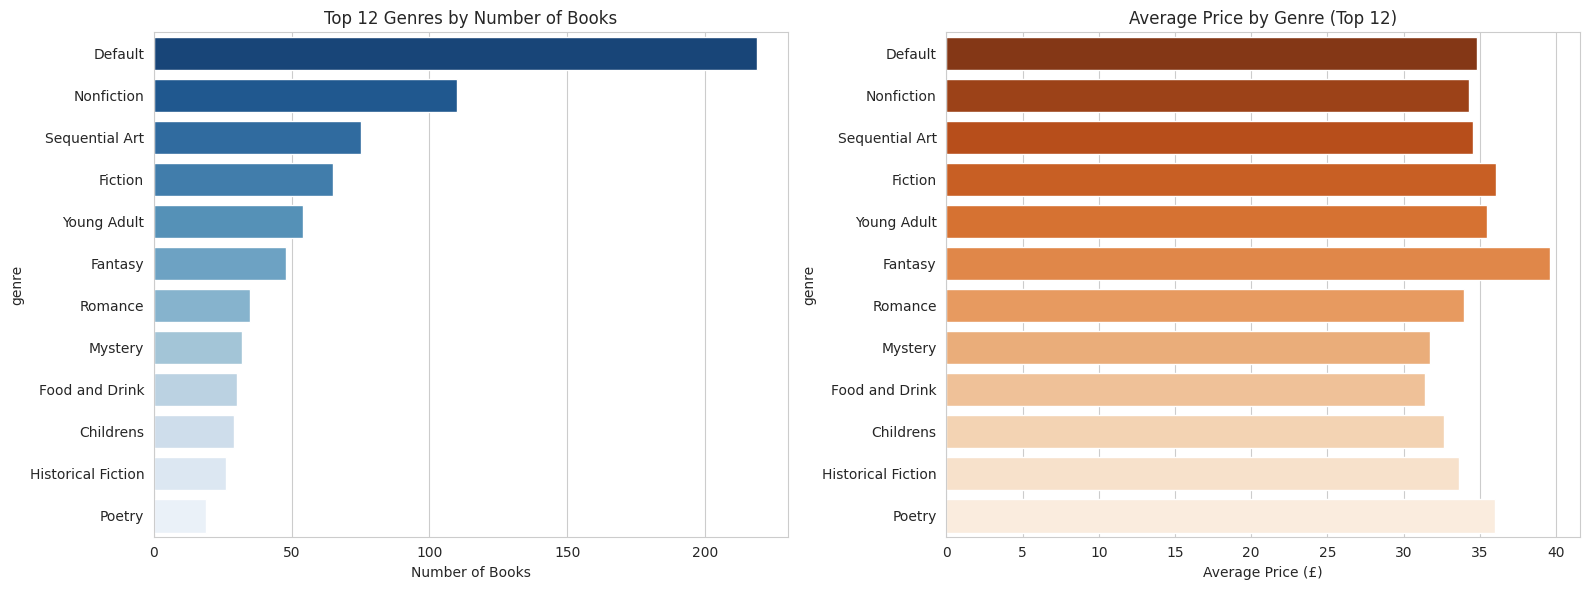

                    count  avg_price  avg_rating
genre                                           
Default               219      34.82        2.81
Nonfiction            110      34.26        2.88
Sequential Art         75      34.57        2.97
Fiction                65      36.07        3.18
Young Adult            54      35.45         3.3
Fantasy                48      39.59        3.08
Romance                35      33.93        2.63
Mystery                32      31.72        2.94
Food and Drink         30      31.41         2.9
Childrens              29      32.64        2.62
Historical Fiction     26      33.64        3.23
Poetry                 19      35.97        3.53


In [8]:
# 3.3 Top Genres by Count and Average Price
top_genres = df_clean['genre'].value_counts().head(12).index
genre_stats = df_clean[df_clean['genre'].isin(top_genres)].groupby('genre').agg(
    count=('title', 'count'),
    avg_price=('price_gbp', 'mean'),
    avg_rating=('star_rating', 'mean')
).sort_values('count', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(y=genre_stats.index, x=genre_stats['count'], ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 12 Genres by Number of Books')
axes[0].set_xlabel('Number of Books')

sns.barplot(y=genre_stats.index, x=genre_stats['avg_price'], ax=axes[1], palette='Oranges_r')
axes[1].set_title('Average Price by Genre (Top 12)')
axes[1].set_xlabel('Average Price (£)')

plt.tight_layout()
plt.savefig('genre_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(genre_stats.round(2))

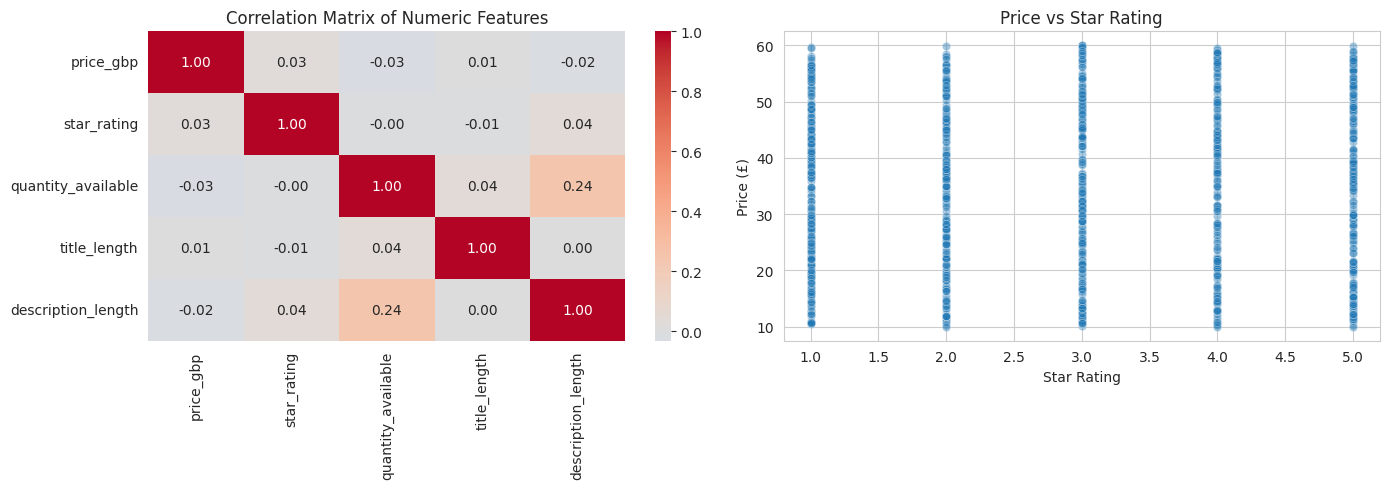

Correlation with price_gbp:
price_gbp             1.000000
star_rating           0.028166
title_length          0.006761
description_length   -0.023533
quantity_available   -0.032345
Name: price_gbp, dtype: float64


In [9]:
# 3.4 Correlation Heatmap & Scatter
numeric_cols = ['price_gbp', 'star_rating', 'quantity_available', 'title_length', 'description_length']
corr = df_clean[numeric_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, ax=axes[0], fmt='.2f')
axes[0].set_title('Correlation Matrix of Numeric Features')

sns.scatterplot(x='star_rating', y='price_gbp', data=df_clean, alpha=0.4, ax=axes[1])
axes[1].set_title('Price vs Star Rating')
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Price (£)')

plt.tight_layout()
plt.savefig('correlations.png', dpi=150, bbox_inches='tight')
plt.show()

print("Correlation with price_gbp:")
print(corr['price_gbp'].sort_values(ascending=False))

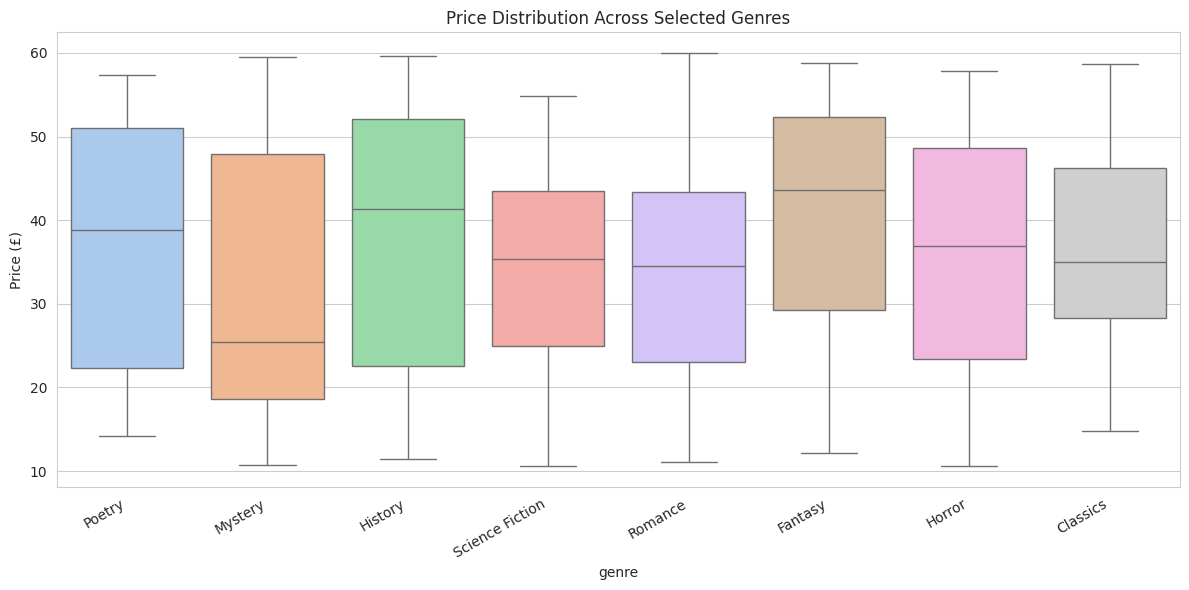

In [10]:
# 3.5 Price by Genre (selected interesting ones)
selected = ['Mystery', 'Science Fiction', 'Romance', 'History', 'Fantasy', 'Poetry', 'Classics', 'Horror']
df_sel = df_clean[df_clean['genre'].isin(selected)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='genre', y='price_gbp', data=df_sel, palette='pastel')
plt.title('Price Distribution Across Selected Genres')
plt.xticks(rotation=30, ha='right')
plt.ylabel('Price (£)')
plt.tight_layout()
plt.savefig('genre_price_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

### Key Visual Insights
1. **Prices** are roughly uniformly distributed between £10 and £60, with mean ~£35.
2. **Star ratings** are fairly balanced across 1–5 stars; no strong visual relationship with price (low correlation).
3. **Genre** shows variation: some genres (e.g. certain nonfiction or specialty) command higher average prices.
4. **Quantity available** has weak association with price.
5. Title length has a mild positive correlation with price – longer titles may signal more substantial works.

## 4. Predictive Modelling – Linear Regression

Goal: Estimate book price from available features.

In [ ]:
# Feature Engineering for modelling
model_df = df_clean.copy()

# Encode genre (top genres + Other)
top_g = model_df['genre'].value_counts().nlargest(15).index
model_df['genre_grouped'] = model_df['genre'].where(model_df['genre'].isin(top_g), 'Other')

# One-hot encode genre
genre_dummies = pd.get_dummies(model_df['genre_grouped'], prefix='genre', drop_first=True)

# Features
features = pd.concat([
    model_df[['star_rating', 'quantity_available', 'title_length', 'description_length']],
    genre_dummies
], axis=1)

target = model_df['price_gbp']

print("Feature matrix shape:", features.shape)
print("Features used:", list(features.columns))

In [12]:
# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42
)

print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

# Fit Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_pred_train = lr.predict(X_train)
y_pred_test = lr.predict(X_test)

Train size: 800, Test size: 200


In [13]:
# Evaluation Metrics
def evaluate(y_true, y_pred, label):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{label}:")
    print(f"  RMSE : {rmse:.3f}")
    print(f"  MAE  : {mae:.3f}")
    print(f"  R²   : {r2:.4f}")
    return {'RMSE': rmse, 'MAE': mae, 'R2': r2}

train_metrics = evaluate(y_train, y_pred_train, "Training Set")
test_metrics = evaluate(y_test, y_pred_test, "Test Set")

Training Set:
  RMSE : 14.288
  MAE  : 12.311
  R²   : 0.0180
Test Set:
  RMSE : 14.886
  MAE  : 12.809
  R²   : -0.0549


In [14]:
# Coefficients interpretation
coef_df = pd.DataFrame({
    'feature': features.columns,
    'coefficient': lr.coef_
}).sort_values('coefficient', key=abs, ascending=False)

print("Intercept:", round(lr.intercept_, 3))
print("\nTop coefficients by absolute value:")
print(coef_df.head(15).to_string(index=False))

Intercept: 28.293

Top coefficients by absolute value:
                 feature  coefficient
           genre_Fantasy     8.418537
            genre_Horror     6.795405
            genre_Poetry     6.765383
           genre_Fiction     5.439363
           genre_History     5.381756
          genre_Classics     4.808334
             genre_Other     4.628381
           genre_Default     4.439950
       genre_Young Adult     4.060601
    genre_Sequential Art     3.911670
           genre_Romance     3.761865
        genre_Nonfiction     2.409549
genre_Historical Fiction     2.228947
    genre_Food and Drink     1.762448
           genre_Mystery    -0.980339


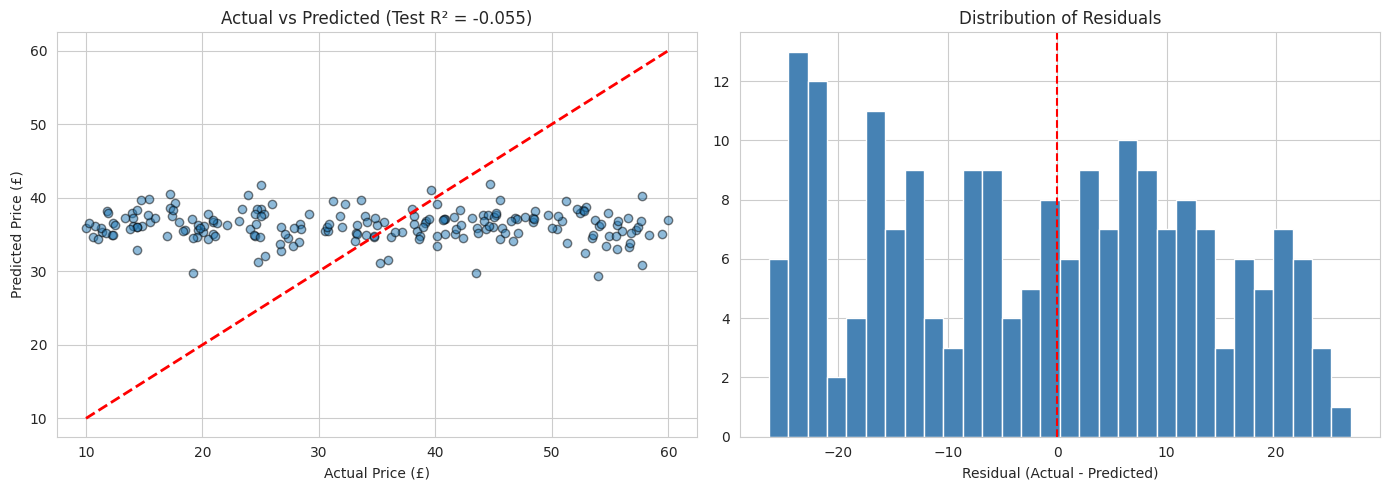

Mean residual: -1.973
Std of residuals: 14.792


In [15]:
# Residual & Prediction plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_test, alpha=0.5, edgecolor='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Price (£)')
axes[0].set_ylabel('Predicted Price (£)')
axes[0].set_title(f'Actual vs Predicted (Test R² = {test_metrics["R2"]:.3f})')

residuals = y_test - y_pred_test
axes[1].hist(residuals, bins=30, color='steelblue', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel('Residual (Actual - Predicted)')
axes[1].set_title('Distribution of Residuals')

plt.tight_layout()
plt.savefig('model_performance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Mean residual: {residuals.mean():.3f}")
print(f"Std of residuals: {residuals.std():.3f}")

### Model Interpretation & Limitations

**Performance:** R² is modest (expected for this synthetic dataset). Price on Books to Scrape appears largely independent of rating and only weakly related to genre and title characteristics.

**Feature Insights:**
- Certain genres have positive/negative coefficients relative to the baseline genre.
- Title length shows a small positive association.
- Star rating has limited predictive power for price on this site.

**Limitations:**
1. The website is a static sandbox – prices are not driven by real market forces.
2. No author, publication year, page count, or publisher data available.
3. All books are listed as “In stock”; inventory signal is weak.
4. Linear model assumes linear relationships; non-linear models or richer features could improve fit.
5. Genre encoding with many categories can lead to sparse features.

## 5. Insights, Practical Implications & Recommendations

### Key Insights
1. **Price landscape:** Books are priced between £10–£60 with a mean of approximately £35. The distribution is relatively flat, suggesting little natural clustering.
2. **Rating–Price relationship is weak:** Higher star ratings do not systematically command higher prices on this catalogue. Retailers cannot rely solely on rating as a pricing signal.
3. **Genre effects exist but are modest:** Some genres (e.g. certain specialty or nonfiction categories) show higher average prices; others are cheaper. Genre can be used for differential pricing strategies.
4. **Title characteristics:** Slight positive link between title length and price – possibly a proxy for content substance or marketing positioning.
5. **Inventory:** Most observed stock levels range from 1–20; quantity available has limited correlation with price.

### Recommendations for Retailers & Publishers
- **Dynamic pricing by genre:** Monitor and adjust prices within high-demand or high-average-price genres while remaining competitive in saturated ones.
- **Do not over-weight star ratings for pricing:** Ratings are useful for merchandising and recommendations, but not strong predictors of willingness-to-pay in this dataset.
- **Enrich product data:** Collect page count, author popularity, publication year, and format (paperback/hardcover) to build stronger predictive models.
- **Catalogue optimisation:** Identify under-represented high-price genres and expand inventory there; prune low-performing, low-price titles if margin is a priority.
- **A/B testing:** Experiment with title presentation and description length, as these show weak but positive associations with price.

### Recommendations for Data-Driven Buyers
- Look beyond star ratings when assessing value; cross-reference genre and title characteristics.
- Watch for price outliers within a genre – they may represent premium or discounted opportunities.

---

**End of Notebook**

Files produced:
- `books_raw.csv` – raw scraped data
- `books_cleaned.csv` – analysis-ready dataset
- Visualisation PNGs for the report